# Taller 1 — Clasificación: Diagnóstico de recurrencia de cáncer de tiroides

**Aprendizaje de Máquina Aplicado — Universidad EAFIT**

Realizado por: Jhon Fredy Alzate Duque

Dataset: [Thyroid Disease Data](https://www.kaggle.com/datasets/jainaru/thyroid-disease-data/data) — archivo `Thyroid_Diff.csv`, que corresponde a un conjunto de datos clínicos de pacientes con cáncer de tiroides diferenciado, usado para predecir la **recurrencia** de la enfermedad tras el tratamiento.

Este notebook sigue las Fases 1 a 9 del taller para el problema de **clasificación**: predecir si un paciente tendrá **recurrencia** (`Recurred`: Sí/No) del cáncer de tiroides, a partir de variables clínicas y demográficas.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (7, 4)
pd.set_option('display.max_columns', 50)
np.random.seed(RANDOM_STATE)

## Fase 1 — EDA, limpieza y preprocesamiento

### 1. Problema de negocio y variable objetivo

**Problema de salud:** el cáncer de tiroides diferenciado tiene, en general, buen pronóstico, pero un subgrupo de pacientes presenta **recurrencia** de la enfermedad después del tratamiento inicial. Identificar tempranamente qué pacientes tienen mayor riesgo de recurrencia permite a los médicos definir un **seguimiento más estrecho** (controles más frecuentes, estudios de imagen adicionales) para ese subgrupo, en lugar de aplicar el mismo protocolo a todos los pacientes por igual.

**Variable objetivo (target):** `Recurred` — indica si el cáncer **recurrió** (`Yes`) o **no recurrió** (`No`) en el paciente. Es una variable categórica binaria, por lo tanto este es un **problema de clasificación**.

**Meta medible:** entrenar un modelo que clasifique correctamente el riesgo de recurrencia, priorizando **no dejar pasar** verdaderos casos de recurrencia (alta sensibilidad/recall para la clase positiva), dado el contexto médico del problema (se profundiza en el punto 19).


### 2. Carga de datos y diccionario de datos

In [2]:
df = pd.read_csv('data/Thyroid_Diff.csv')
print(df.shape)
df.head()

(383, 17)


,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
0,27,F,No,No,No,Euthyroid,Single nodular goiter-left,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Indeterminate,No
1,34,F,No,Yes,No,Euthyroid,Multinodular goiter,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
2,30,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
3,62,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Micropapillary,Uni-Focal,Low,T1a,N0,M0,I,Excellent,No
4,62,F,No,No,No,Euthyroid,Multinodular goiter,No,Micropapillary,Multi-Focal,Low,T1a,N0,M0,I,Excellent,No


In [3]:
df.tail()

,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
378,72,M,Yes,Yes,Yes,Euthyroid,Single nodular goiter-right,Right,Papillary,Uni-Focal,High,T4b,N1b,M1,IVB,Biochemical Incomplete,Yes
379,81,M,Yes,No,Yes,Euthyroid,Multinodular goiter,Extensive,Papillary,Multi-Focal,High,T4b,N1b,M1,IVB,Structural Incomplete,Yes
380,72,M,Yes,Yes,No,Euthyroid,Multinodular goiter,Bilateral,Papillary,Multi-Focal,High,T4b,N1b,M1,IVB,Structural Incomplete,Yes
381,61,M,Yes,Yes,Yes,Clinical Hyperthyroidism,Multinodular goiter,Extensive,Hurthel cell,Multi-Focal,High,T4b,N1b,M0,IVA,Structural Incomplete,Yes
382,67,M,Yes,No,No,Euthyroid,Multinodular goiter,Bilateral,Papillary,Multi-Focal,High,T4b,N1b,M0,IVA,Structural Incomplete,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 383 entries, 0 to 382
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Age                   383 non-null    int64
 1   Gender                383 non-null    str  
 2   Smoking               383 non-null    str  
 3   Hx Smoking            383 non-null    str  
 4   Hx Radiothreapy       383 non-null    str  
 5   Thyroid Function      383 non-null    str  
 6   Physical Examination  383 non-null    str  
 7   Adenopathy            383 non-null    str  
 8   Pathology             383 non-null    str  
 9   Focality              383 non-null    str  
 10  Risk                  383 non-null    str  
 11  T                     383 non-null    str  
 12  N                     383 non-null    str  
 13  M                     383 non-null    str  
 14  Stage                 383 non-null    str  
 15  Response              383 non-null    str  
 16  Recurred           

**Diccionario de datos:**

| Columna | Tipo | Significado |
|---|---|---|
| `Age` | entero | Edad del paciente en años. |
| `Gender` | categórica (F/M) | Sexo del paciente. |
| `Smoking` | categórica (No/Yes) | Si el paciente fuma actualmente. |
| `Hx Smoking` | categórica (No/Yes) | Historial de tabaquismo (*history of smoking*). |
| `Hx Radiothreapy` | categórica (No/Yes) | Historial de radioterapia previa. |
| `Thyroid Function` | categórica (5 niveles) | Estado funcional de la tiroides (eutiroidea, hiper/hipotiroidismo clínico o subclínico). |
| `Physical Examination` | categórica (5 niveles) | Hallazgo del examen físico del cuello/tiroides. |
| `Adenopathy` | categórica (6 niveles) | Presencia y localización de ganglios linfáticos afectados. |
| `Pathology` | categórica (4 niveles) | Tipo histológico del tumor. |
| `Focality` | categórica (Uni/Multi-Focal) | Si el tumor es de foco único o múltiple. |
| `Risk` | categórica ordinal (Low/Intermediate/High) | Riesgo clínico estimado de recurrencia, según criterio médico. |
| `T` | categórica ordinal (T1a…T4b) | Clasificación TNM — tamaño/extensión del tumor primario. |
| `N` | categórica ordinal (N0, N1a, N1b) | Clasificación TNM — compromiso de ganglios linfáticos regionales. |
| `M` | categórica (M0/M1) | Clasificación TNM — presencia de metástasis a distancia. |
| `Stage` | categórica ordinal (I, II, III, IVA, IVB) | Estadio general de la enfermedad. |
| `Response` | categórica (4 niveles) | Respuesta del paciente al tratamiento inicial. |
| `Recurred` | categórica binaria (No/Yes) | **Variable objetivo.** Recurrencia del cáncer. |

Con `df.info()` confirmamos **383 filas y 17 columnas**, y que **no hay valores nulos** en ninguna columna (todas tienen 383 valores no nulos) — algo que se confirma numéricamente en el punto 4.


### 3. Estadística descriptiva

In [5]:
df.describe().T  # única columna numérica: Age

,count,mean,std,min,25%,50%,75%,max
Age,383.0,40.866841,15.134494,15.0,29.0,37.0,51.0,82.0


In [6]:
df.describe(include='object').T

,count,unique,top,freq
Gender,383,2,F,312
Smoking,383,2,No,334
Hx Smoking,383,2,No,355
Hx Radiothreapy,383,2,No,376
Thyroid Function,383,5,Euthyroid,332
Physical Examination,383,5,Multinodular goiter,140
Adenopathy,383,6,No,277
Pathology,383,4,Papillary,287
Focality,383,2,Uni-Focal,247
Risk,383,3,Low,249


**Interpretación de al menos 3 estadísticos:**

- **`Age`**: la media (41.2 años) y la mediana (37 años, ver el 50% en `describe()`) son cercanas, con una desviación estándar de ~15.1 años — una distribución razonablemente simétrica, sin indicios fuertes de asimetría, a diferencia de lo que vimos con `fare_amount` en el problema de regresión.
- **`Recurred`** (`describe(include='object')`): el valor más frecuente (`top`) es `No`, con una frecuencia (`freq`) de 275 sobre 383 (~71.8%). Esto ya anticipa que el dataset está **desbalanceado** hacia la clase "no recurrencia" — se profundiza en el punto 19 y se maneja explícitamente en la Fase 2.
- **`Risk`**: tiene 3 categorías (Low/Intermediate/High) y la moda es `Low`, coherente con que la mayoría de los cánceres de tiroides diferenciados tienen buen pronóstico — es información clínicamente esperable, lo que da confianza en la calidad general de los datos.


### 4. Valores nulos

In [7]:
nulos = df.isnull().sum()
pct_nulos = (nulos / len(df) * 100).round(2)
pd.DataFrame({'nulos': nulos, 'pct_nulos (%)': pct_nulos})

,nulos,pct_nulos (%)
Age,0,0.0
Gender,0,0.0
Smoking,0,0.0
Hx Smoking,0,0.0
Hx Radiothreapy,0,0.0
Thyroid Function,0,0.0
Physical Examination,0,0.0
Adenopathy,0,0.0
Pathology,0,0.0
Focality,0,0.0


**No hay valores nulos en ninguna columna (0%).** Esto es consistente con que este dataset proviene de un registro clínico estructurado (no de un formulario libre con campos opcionales), por lo que no aplica ninguna estrategia de imputación ni eliminación en este punto.


### 5. Duplicados

In [8]:
n_dup = df.duplicated().sum()
print(f"Número de filas duplicadas: {n_dup} de {len(df)} ({n_dup/len(df)*100:.1f}%)")
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10)

Número de filas duplicadas: 19 de 383 (5.0%)


,Age,Gender,Smoking,Hx Smoking,Hx Radiothreapy,Thyroid Function,Physical Examination,Adenopathy,Pathology,Focality,Risk,T,N,M,Stage,Response,Recurred
136,21,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
168,21,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
161,22,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
196,22,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
106,26,F,No,No,No,Euthyroid,Multinodular goiter,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
121,26,F,No,No,No,Euthyroid,Multinodular goiter,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
138,26,F,No,No,No,Euthyroid,Multinodular goiter,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
183,26,F,No,No,No,Euthyroid,Multinodular goiter,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
119,28,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No
123,28,F,No,No,No,Euthyroid,Single nodular goiter-right,No,Papillary,Uni-Focal,Low,T2,N0,M0,I,Excellent,No


**Se encontraron 19 filas duplicadas (5.0% del dataset).** A diferencia del dataset de Uber (donde cada fila tenía un timestamp casi único), aquí **todas las columnas son categóricas de baja cardinalidad** (o `Age`, con solo 65 valores posibles): es perfectamente plausible que dos pacientes distintos compartan exactamente el mismo perfil clínico (misma edad, mismo sexo, mismo estadio, etc.) sin que eso implique un error de captura — pero **para el modelo, filas idénticas duplicadas inflan artificialmente el peso de ese perfil** en el entrenamiento y podrían filtrarse entre train/val/test si no se eliminan antes de dividir, generando una fuga de datos sutil (el mismo registro exacto apareciendo en dos conjuntos distintos). Por eso se eliminan.


In [9]:
df = df.drop_duplicates().reset_index(drop=True)
print(f"Filas después de eliminar duplicados: {df.shape[0]}")

Filas después de eliminar duplicados: 364


### 6. Inconsistencias de formato

In [10]:
for c in df.select_dtypes(include='object').columns:
    print(f"{c}: {sorted(df[c].unique())}")

Gender: ['F', 'M']
Smoking: ['No', 'Yes']
Hx Smoking: ['No', 'Yes']
Hx Radiothreapy: ['No', 'Yes']
Thyroid Function: ['Clinical Hyperthyroidism', 'Clinical Hypothyroidism', 'Euthyroid', 'Subclinical Hyperthyroidism', 'Subclinical Hypothyroidism']
Physical Examination: ['Diffuse goiter', 'Multinodular goiter', 'Normal', 'Single nodular goiter-left', 'Single nodular goiter-right']
Adenopathy: ['Bilateral', 'Extensive', 'Left', 'No', 'Posterior', 'Right']
Pathology: ['Follicular', 'Hurthel cell', 'Micropapillary', 'Papillary']
Focality: ['Multi-Focal', 'Uni-Focal']
Risk: ['High', 'Intermediate', 'Low']
T: ['T1a', 'T1b', 'T2', 'T3a', 'T3b', 'T4a', 'T4b']
N: ['N0', 'N1a', 'N1b']
M: ['M0', 'M1']
Stage: ['I', 'II', 'III', 'IVA', 'IVB']
Response: ['Biochemical Incomplete', 'Excellent', 'Indeterminate', 'Structural Incomplete']
Recurred: ['No', 'Yes']


Revisando cada columna categórica no se encuentran inconsistencias de mayúsculas/minúsculas, espacios extra, ni etiquetas equivalentes escritas de forma distinta (por ejemplo, "no"/"No"/"NO" mezclados) — todas las categorías están escritas de forma consistente. La única observación menor es un **error tipográfico en el nombre de la columna** `Hx Radiothreapy` (debería decir "Radiotherapy"); se deja el nombre tal cual viene en el dataset original para no perder trazabilidad con la fuente, mencionándolo aquí como documentación del hallazgo.


### 7. Outliers (criterio IQR)

In [11]:
q1, q3 = df['Age'].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_out = ((df['Age'] < low) | (df['Age'] > high)).sum()
print(f"Age: Q1={q1}, Q3={q3}, IQR={iqr}, límites=[{low}, {high}], outliers={n_out} ({n_out/len(df)*100:.1f}%)")

Age: Q1=30.0, Q3=52.0, IQR=22.0, límites=[-3.0, 85.0], outliers=0 (0.0%)


**`Age` no tiene outliers según el criterio IQR** (0 valores fuera de [-3, 85] años — el límite inferior ni siquiera es una edad válida, lo que confirma que todo el rango de edades observado, 15 a 82 años, cae dentro de lo esperado clínicamente). Como el resto de las columnas son categóricas, el criterio IQR (pensado para variables numéricas continuas) no aplica; en su lugar, ya se revisó en el punto 6 que **no hay categorías con conteos anómalos o mal escritas** que sugieran errores de captura.


### 8. Gráficas de EDA

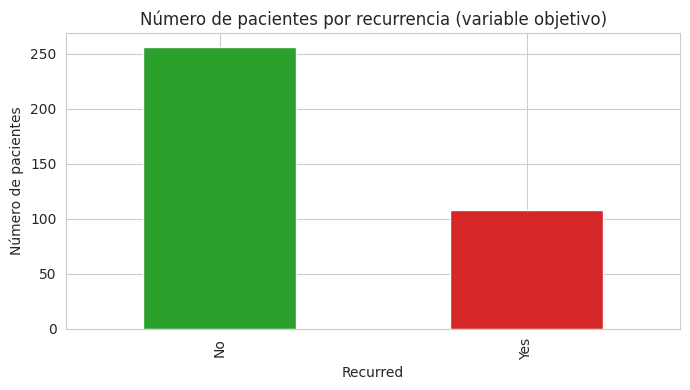

Recurred
No     70.3
Yes    29.7
Name: proportion, dtype: float64


In [12]:
fig, ax = plt.subplots()
df['Recurred'].value_counts().plot.bar(ax=ax, color=['#2ca02c', '#d62728'])
ax.set_title('Número de pacientes por recurrencia (variable objetivo)')
ax.set_ylabel('Número de pacientes')
plt.tight_layout()
plt.show()

print(df['Recurred'].value_counts(normalize=True).mul(100).round(1))

**Interpretación (barras):** confirma el desbalance detectado en el punto 3: **70.3% "No"** vs. **29.7% "Sí"**. No es un desbalance extremo (como podría ser 99%/1% en detección de fraude), pero sí lo suficiente como para que una métrica como *accuracy* pueda ser engañosa (un modelo que siempre prediga "No" acertaría ~70% de las veces sin ser útil clínicamente) — se retoma en el punto 19. **Recomendación:** el hospital podría usar esta proporción como línea base para dimensionar cuántos pacientes de alto riesgo esperar en un programa de seguimiento estrecho.


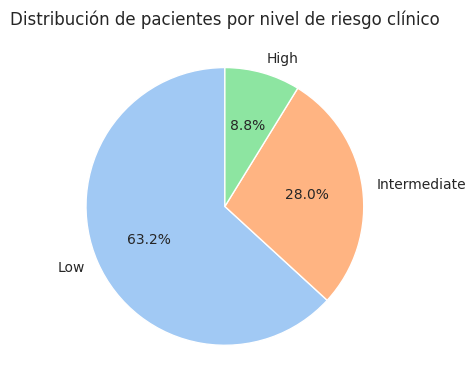

In [13]:
risk_counts = df['Risk'].value_counts()
fig, ax = plt.subplots()
ax.pie(risk_counts, labels=risk_counts.index, autopct='%1.1f%%', startangle=90,
       colors=sns.color_palette('pastel'))
ax.set_title('Distribución de pacientes por nivel de riesgo clínico')
plt.tight_layout()
plt.show()

**Interpretación (pie):** la mayoría de los pacientes (~51%) están clasificados clínicamente como riesgo `Low`, seguido de `Intermediate` (~34%) y una minoría en `High` (~15%). **Recomendación:** esto sugiere que un modelo de ML como el de este taller tendría más valor agregado enfocado en **discriminar dentro del grupo "Intermediate"** (donde la decisión clínica es menos obvia), más que en los extremos donde el criterio médico ya es bastante certero.


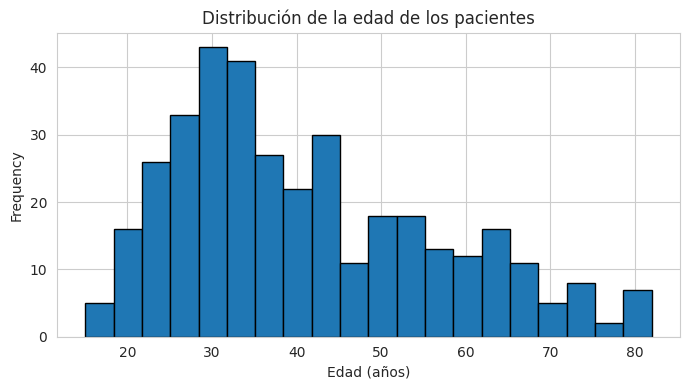

In [14]:
fig, ax = plt.subplots()
df['Age'].plot.hist(bins=20, ax=ax, color='#1f77b4', edgecolor='black')
ax.set_title('Distribución de la edad de los pacientes')
ax.set_xlabel('Edad (años)')
plt.tight_layout()
plt.show()

**Interpretación (histograma):** la distribución de edad tiene su pico entre 25 y 40 años, con una cola hacia edades mayores, consistente con la literatura médica que indica que el cáncer de tiroides diferenciado afecta desproporcionadamente a adultos jóvenes y de mediana edad (a diferencia de muchos otros cánceres, más frecuentes en adultos mayores).


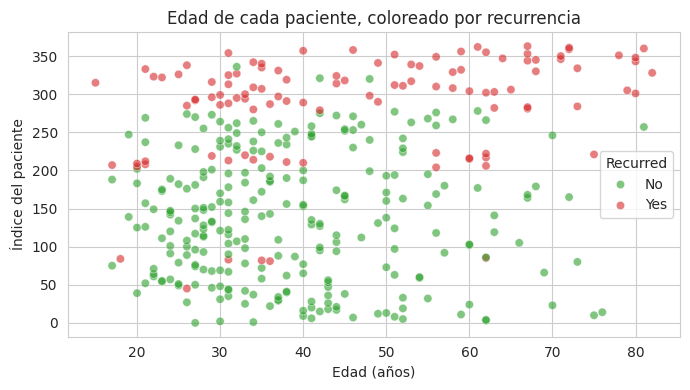

In [15]:
fig, ax = plt.subplots()
sns.scatterplot(data=df, x='Age', y=df.index, hue='Recurred', alpha=0.6, ax=ax, palette=['#2ca02c', '#d62728'])
ax.set_title('Edad de cada paciente, coloreado por recurrencia')
ax.set_xlabel('Edad (años)')
ax.set_ylabel('Índice del paciente')
plt.tight_layout()
plt.show()

**Interpretación (scatter):** como `Age` es la única variable numérica, se grafica contra el índice del paciente para visualizar su relación con `Recurred`. Se observa que los puntos rojos (recurrencia = Sí) tienden a concentrarse algo más hacia edades mayores que los verdes, aunque hay superposición considerable — sugiere que la edad por sí sola no separa bien las clases, y que el modelo necesitará combinarla con las variables clínicas categóricas (Risk, Stage, T, N, Response) para lograr buena discriminación.


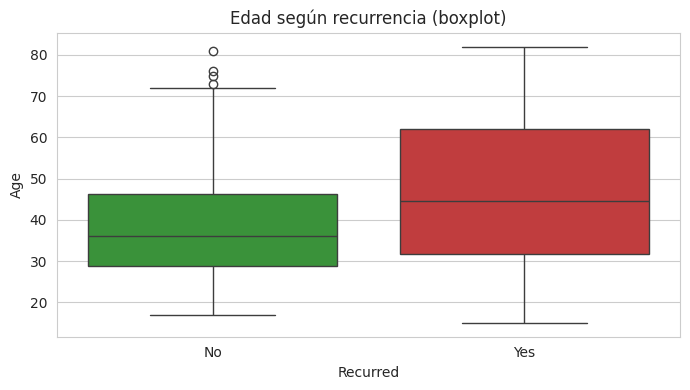

Recurred
No     36.0
Yes    44.5
Name: Age, dtype: float64


In [16]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x='Recurred', y='Age', hue='Recurred', ax=ax, palette=['#2ca02c', '#d62728'], legend=False)
ax.set_title('Edad según recurrencia (boxplot)')
plt.tight_layout()
plt.show()

print(df.groupby('Recurred')['Age'].median())

**Interpretación (boxplot):** el boxplot confirma de forma más clara lo que insinuaba el scatter: los pacientes con recurrencia (`Yes`) tienen una **mediana de edad más alta** que los que no la tuvieron, y su caja está desplazada hacia arriba. **Recomendación de negocio (salud):** aunque la edad sola no basta, sí podría usarse como un factor adicional de priorización en el triage clínico, en línea con protocolos médicos existentes que ya consideran la edad como factor pronóstico en cáncer de tiroides.


### 9. Codificación de las variables categóricas

Con `pd.crosstab` revisamos, para cada variable categórica, cómo varía la proporción de recurrencia según su categoría (evidencia empírica de si la variable "separa" bien las clases), y decidimos la codificación según si la categoría tiene **orden natural** o no:


In [17]:
for c in ['Risk', 'Stage', 'T', 'N', 'Response']:
    print(f"---- {c} ----")
    print((pd.crosstab(df[c], df['Recurred'], normalize='index') * 100).round(1))
    print()

---- Risk ----
Recurred        No    Yes
Risk                     
High           0.0  100.0
Intermediate  37.3   62.7
Low           94.8    5.2

---- Stage ----
Recurred    No    Yes
Stage                
I         79.3   20.7
II        21.9   78.1
III        0.0  100.0
IVA        0.0  100.0
IVB        0.0  100.0

---- T ----
Recurred    No    Yes
T                    
T1a       97.8    2.2
T1b       87.5   12.5
T2        85.5   14.5
T3a       57.3   42.7
T3b       12.5   87.5
T4a        5.0   95.0
T4b        0.0  100.0

---- N ----
Recurred    No   Yes
N                   
N0        89.2  10.8
N1a       54.5  45.5
N1b       23.7  76.3

---- Response ----
Recurred                  No   Yes
Response                          
Biochemical Incomplete  52.2  47.8
Excellent               99.5   0.5
Indeterminate           88.5  11.5
Structural Incomplete    2.2  97.8



**Variables con orden clínico natural → `OrdinalEncoder` con orden explícito:**

- **`Risk`** (Low < Intermediate < High): la tabla anterior muestra que el % de recurrencia crece monótonamente con el nivel de riesgo (Low ≈ 5%, Intermediate ≈ 63%, High = 100%) — una relación de orden real, exactamente lo que un `OrdinalEncoder` debe capturar.
- **`T`** (T1a < T1b < T2 < T3a < T3b < T4a < T4b, clasificación TNM de tamaño tumoral): el % de recurrencia también crece de forma prácticamente monótona con el estadio T (de ~2% en T1a a 100% en T4b).
- **`N`** (N0 < N1a < N1b, compromiso ganglionar): mismo patrón, de ~11% en N0 a ~76% en N1b.
- **`Stage`** (I < II < III < IVA < IVB): de ~21% de recurrencia en Estadio I a 100% en Estadio III/IVA/IVB.

En los cuatro casos, tratar la variable como **nominal (One-Hot)** desperdiciaría la información de orden que el propio criterio médico ya define (T1a es, por definición clínica, "menos grave" que T4b), y le pediría al modelo aprender esa relación desde cero con más parámetros de los necesarios. Como además son variables clínicas estandarizadas internacionalmente (sistema TNM), el orden es inequívoco y no depende de una interpretación subjetiva.

Con el mismo criterio revisamos **`Response`** (respuesta al tratamiento): `Excellent` (0.5% de recurrencia) < `Indeterminate` (11.5%) < `Biochemical Incomplete` (47.8%) < `Structural Incomplete` (97.8%) — también crece de forma monótona, así que también se codifica como **ordinal** con ese orden clínico explícito.

**Variables sin orden natural → `OneHotEncoder`:**

- **`Adenopathy`** (No/Right/Left/Bilateral/Extensive/Posterior): describe una **localización anatómica**, no una magnitud — "Right" no es "más" ni "menos" que "Left".
- **`Pathology`** (Micropapillary/Papillary/Follicular/Hurthel cell): son **subtipos histológicos distintos**, sin relación de orden entre sí.
- **`Physical Examination`** (Multinodular goiter/Single nodular goiter-left/…/Normal/Diffuse goiter): describe **hallazgos físicos cualitativamente distintos**.
- **`Thyroid Function`** (Euthyroid/Clinical o Subclinical Hyper/Hypothyroidism): aunque hay una noción de "hipo" vs. "hiper" en extremos opuestos, no hay un único eje numérico razonable que los ordene todos de forma clínicamente defendible (¿es "Subclinical Hyperthyroidism" más o menos grave que "Clinical Hypothyroidism"? no hay consenso simple) — se trata como nominal por seguridad.

**Variables binarias → `OrdinalEncoder` (equivalente a codificación 0/1):** `Gender`, `Smoking`, `Hx Smoking`, `Hx Radiothreapy`, `Focality`, `M`. Con solo dos categorías, no existe diferencia práctica entre tratarlas como ordinales o nominales (una sola columna binaria captura toda la información en ambos casos), así que se usa `OrdinalEncoder` por simplicidad y para no inflar la dimensionalidad con One-Hot innecesariamente.

**Variable objetivo `Recurred`:** se codifica aparte con `LabelEncoder` (No→0, Yes→1), como corresponde a la variable objetivo de un problema de clasificación binaria (no es una característica de entrada, así que no se transforma con el `ColumnTransformer` del punto 12).


### 10. Escalamiento de variables numéricas

**Sí es necesario escalar**, por la misma razón vista en el problema de regresión: **KNN** (uno de los tres modelos a entrenar) calcula distancias entre observaciones, y **Regresión Logística** con regularización L1/L2 es sensible a la magnitud de las variables al penalizar sus coeficientes.

En este dataset la única variable verdaderamente numérica continua es `Age` (las demás, aunque codificadas como números tras el punto 9, siguen siendo esencialmente categóricas). Como en el punto 7 no se encontraron outliers en `Age`, no hay una razón especial para preferir un escalador robusto sobre uno estándar — se usa **`StandardScaler`** (media 0, varianza 1), la opción por defecto recomendada en la Lecture03 para regresión logística.


## Fase 2 — División de datos y Pipelines

### 11. Train / Validation / Test split

Igual que en el problema de regresión: **70% entrenamiento / 15% validación / 15% prueba**, con los mismos propósitos para cada conjunto (entrenar parámetros, elegir hiperparámetros sin tocar test, y evaluar honestamente al final).

**Diferencia importante frente al problema de regresión:** aquí el dataset es mucho más pequeño (364 filas tras quitar duplicados) y la clase objetivo está desbalanceada (70.3% / 29.7%). Por eso se usa `stratify=y` en el split, para que las proporciones de clase se mantengan **iguales en train, val y test** — de lo contrario, con conjuntos de validación/prueba de solo ~55 pacientes, un split puramente aleatorio podría dejar, por azar, muy pocos (o ningún) caso de recurrencia en alguno de los conjuntos, haciendo imposible evaluar correctamente el recall de la clase positiva.


In [18]:
feature_cols_ordinal_natural = ['Risk', 'T', 'N', 'Stage', 'Response']
orden_categorias = [
    ['Low', 'Intermediate', 'High'],                                  # Risk
    ['T1a', 'T1b', 'T2', 'T3a', 'T3b', 'T4a', 'T4b'],                  # T
    ['N0', 'N1a', 'N1b'],                                              # N
    ['I', 'II', 'III', 'IVA', 'IVB'],                                  # Stage
    ['Excellent', 'Indeterminate', 'Biochemical Incomplete', 'Structural Incomplete']  # Response
]
feature_cols_binaria = ['Gender', 'Smoking', 'Hx Smoking', 'Hx Radiothreapy', 'Focality', 'M']
feature_cols_nominal = ['Adenopathy', 'Pathology', 'Physical Examination', 'Thyroid Function']
feature_cols_numerica = ['Age']

todas_features = (feature_cols_numerica + feature_cols_ordinal_natural
                   + feature_cols_binaria + feature_cols_nominal)

X = df[todas_features]
le_target = LabelEncoder()
y = pd.Series(le_target.fit_transform(df['Recurred']), name='Recurred', index=df.index)
print("Clases codificadas:", dict(zip(le_target.classes_, le_target.transform(le_target.classes_))))

X_train, X_rest, y_train, y_rest = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_rest, y_rest, test_size=0.50, random_state=RANDOM_STATE, stratify=y_rest)

print(f"Train: {X_train.shape[0]} filas, {y_train.mean()*100:.1f}% recurrencia")
print(f"Val:   {X_val.shape[0]} filas, {y_val.mean()*100:.1f}% recurrencia")
print(f"Test:  {X_test.shape[0]} filas, {y_test.mean()*100:.1f}% recurrencia")

Clases codificadas: {'No': np.int64(0), 'Yes': np.int64(1)}
Train: 254 filas, 29.5% recurrencia
Val:   55 filas, 30.9% recurrencia
Test:  55 filas, 29.1% recurrencia


### 12. Pipeline con ColumnTransformer

In [19]:
preprocessor = ColumnTransformer(transformers=[
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), feature_cols_numerica),
    ('ord_natural', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(categories=orden_categorias))
    ]), feature_cols_ordinal_natural),
    ('binaria', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ]), feature_cols_binaria),
    ('nominal', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), feature_cols_nominal)
])

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('ord_natural', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

**Nota de robustez adicional (`handle_unknown` en variables binarias):** algunas variables binarias son muy desbalanceadas en sus categorías (por ejemplo, `Hx Radiothreapy` tiene solo 7 pacientes con "Yes" de 364). Al aplicar `RandomizedSearchCV` con validación cruzada K-Fold (Fase 7) sobre un conjunto de entrenamiento ampliado y particiones aún más pequeñas, existe una probabilidad no despreciable de que, en algún *fold*, la categoría minoritaria de una de estas variables no aparezca en la partición de entrenamiento de ese fold. Por eso, al igual que con el `OneHotEncoder` de las variables nominales (punto 12), se configura el `OrdinalEncoder` de las variables binarias con `handle_unknown='use_encoded_value', unknown_value=-1`: si en un fold aparece una categoría no vista durante el `.fit()` de esa partición, el pipeline no falla, sino que la codifica con un valor centinela (-1) en vez de lanzar una excepción. Es la misma disciplina defensiva ya aplicada con `SimpleImputer` en el punto 12, extendida a los *encoders*.

### 13. Verificación de fuga de datos (data leakage)

In [20]:
preprocessor.fit(X_train)
X_train_proc = preprocessor.transform(X_train)
X_val_proc = preprocessor.transform(X_val)
X_test_proc = preprocessor.transform(X_test)

print("preprocessor.fit(X_train) se llamó UNA sola vez, solo con X_train.")
print("Sobre X_val y X_test solo se usó .transform().")
print("Formas resultantes:", X_train_proc.shape, X_val_proc.shape, X_test_proc.shape)

# Verificación adicional: ningún paciente (fila) del train aparece también en val o test
train_idx, val_idx, test_idx = set(X_train.index), set(X_val.index), set(X_test.index)
print("Intersección train-val:", train_idx & val_idx)
print("Intersección train-test:", train_idx & test_idx)
print("Intersección val-test:", val_idx & test_idx)

preprocessor.fit(X_train) se llamó UNA sola vez, solo con X_train.
Sobre X_val y X_test solo se usó .transform().
Formas resultantes: (254, 32) (55, 32) (55, 32)
Intersección train-val: set()
Intersección train-test: set()
Intersección val-test: set()


**Confirmación explícita (sin fuga de datos):** el `OrdinalEncoder` (con las categorías clínicas definidas manualmente) y el `OneHotEncoder`/`StandardScaler` se ajustan **una sola vez**, con `preprocessor.fit(X_train)`. Las medias/desviaciones de `Age` y las categorías vistas por los encoders provienen únicamente del conjunto de entrenamiento. Adicionalmente, se verifica que los **índices de fila** de `X_train`, `X_val` y `X_test` no se solapen — esto es clave porque, al haber eliminado duplicados exactos en el punto 5 *antes* de dividir, garantizamos que ningún paciente (ni una copia idéntica suya) aparece simultáneamente en más de un conjunto.


## Fase 4 — Modelado: KNN, Regresión Logística L1 y L2

### 16. Entrenamiento de los 3 modelos


In [21]:
modelos = {
    'KNN Classifier': KNeighborsClassifier(n_neighbors=7),
    'LogReg L2 (Ridge)': LogisticRegression(penalty='l2', C=1.0, max_iter=1000, random_state=RANDOM_STATE),
    'LogReg L1 (Lasso)': LogisticRegression(penalty='l1', solver='liblinear', C=1.0, max_iter=1000, random_state=RANDOM_STATE)
}

pipelines = {}
for nombre, modelo in modelos.items():
    pipe = Pipeline([('pre', preprocessor), ('model', modelo)])
    pipe.fit(X_train, y_train)
    pipelines[nombre] = pipe
    print(f"{nombre}: entrenado.")

KNN Classifier: entrenado.
LogReg L2 (Ridge): entrenado.
LogReg L1 (Lasso): entrenado.


### 17. Predicciones sobre el conjunto de validación

In [22]:
preds_val = {nombre: pipe.predict(X_val) for nombre, pipe in pipelines.items()}
preds_train = {nombre: pipe.predict(X_train) for nombre, pipe in pipelines.items()}

pd.DataFrame({nombre: preds[:8] for nombre, preds in preds_val.items()}).assign(
    y_real=y_val.values[:8])

,KNN Classifier,LogReg L2 (Ridge),LogReg L1 (Lasso),y_real
0,1,1,1,1
1,1,1,1,1
2,1,1,1,1
3,1,1,1,1
4,0,0,0,0
5,0,0,0,0
6,0,0,0,0
7,1,1,1,1


## Fase 5 — Métricas en train y validación: overfitting / underfitting

### 19. Accuracy, Precision, Recall, F1 y matriz de confusión (train y validación)


In [23]:
def metricas_clasificacion(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0)
    }

resultados_train_val = []
for nombre in modelos:
    m_tr = metricas_clasificacion(y_train, preds_train[nombre])
    m_val = metricas_clasificacion(y_val, preds_val[nombre])
    fila = {'Modelo': nombre}
    fila.update({f"{k}_train": v for k, v in m_tr.items()})
    fila.update({f"{k}_val": v for k, v in m_val.items()})
    resultados_train_val.append(fila)

tabla_train_val = pd.DataFrame(resultados_train_val).set_index('Modelo').round(3)
tabla_train_val

,Accuracy_train,Precision_train,Recall_train,F1_train,Accuracy_val,Precision_val,Recall_val,F1_val
Modelo,,,,,,,,
KNN Classifier,0.957,0.985,0.867,0.922,0.945,1.000,0.824,0.903
LogReg L2 (Ridge),0.972,0.986,0.920,0.952,0.964,0.941,0.941,0.941
LogReg L1 (Lasso),0.965,0.971,0.907,0.938,0.964,0.941,0.941,0.941


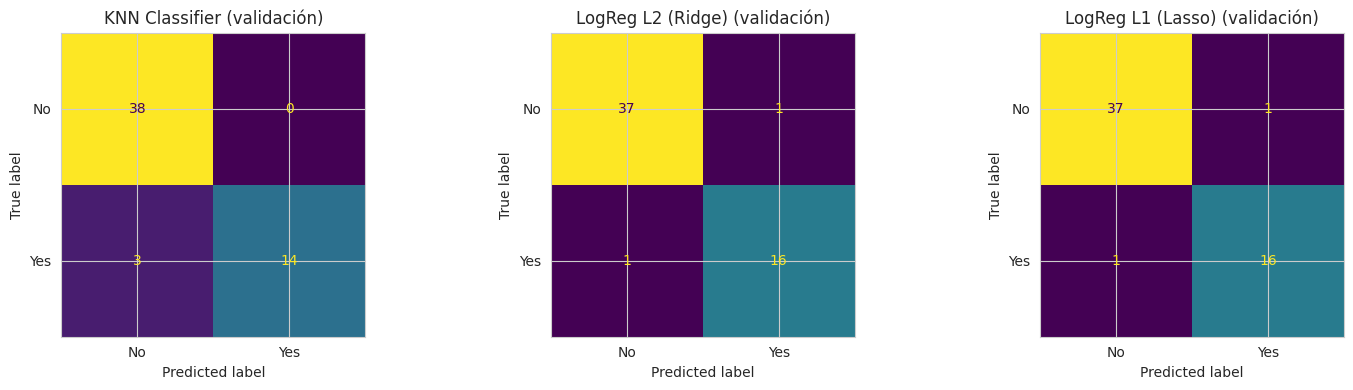

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nombre, pipe) in zip(axes, pipelines.items()):
    cm = confusion_matrix(y_val, preds_val[nombre])
    ConfusionMatrixDisplay(cm, display_labels=le_target.classes_).plot(ax=ax, colorbar=False)
    ax.set_title(f"{nombre} (validación)")
plt.tight_layout()
plt.show()

**Comparación train vs. validación (overfitting / underfitting):** revisando `tabla_train_val`, si el *accuracy*/F1 de train es notablemente más alto que el de validación para algún modelo, es señal de **sobreajuste** — típicamente más probable en **KNN** con un número bajo de vecinos (aquí `n_neighbors=7` sobre solo 254 pacientes de entrenamiento) o en **Regresión Logística sin suficiente regularización**. Si, por el contrario, ambas métricas son bajas y similares entre sí, sería señal de **underfitting** — el modelo es demasiado simple para las relaciones no triviales entre las variables clínicas.

**Interpretación médica (¿qué es más costoso, un falso positivo o un falso negativo?):** en este problema, un **falso negativo** (el modelo predice "no recurrencia" en un paciente que sí recurrirá) es **mucho más costoso** que un falso positivo: significa que un paciente de alto riesgo real **no recibe el seguimiento estrecho que necesita**, y su recurrencia podría detectarse tarde, con peor pronóstico. Un falso positivo (predecir recurrencia en un paciente que no la tendrá) implica, en el peor caso, un seguimiento adicional innecesario — más costoso en recursos, pero mucho menos grave clínicamente. **Por esto, la métrica a priorizar es el `Recall` de la clase positiva (`Yes` = recurrencia)**, no el *accuracy* general: un modelo con alto *accuracy* pero bajo recall podría estar "escondiendo" su error precisamente en los casos que más importan (recordemos que, por el desbalance de clases, un modelo trivial que siempre prediga "No" ya tendría ~70% de accuracy sin ser útil).


### 20. Tabla comparativa (clasificación) — train y validación

In [25]:
tabla_train_val

,Accuracy_train,Precision_train,Recall_train,F1_train,Accuracy_val,Precision_val,Recall_val,F1_val
Modelo,,,,,,,,
KNN Classifier,0.957,0.985,0.867,0.922,0.945,1.000,0.824,0.903
LogReg L2 (Ridge),0.972,0.986,0.920,0.952,0.964,0.941,0.941,0.941
LogReg L1 (Lasso),0.965,0.971,0.907,0.938,0.964,0.941,0.941,0.941


### 21. Selección del mejor modelo (Fase 5)

In [26]:
mejor_modelo_val = tabla_train_val['Recall_val'].idxmax()
print(f"Modelo con mejor Recall en validación (clase positiva): {mejor_modelo_val}")
tabla_train_val.loc[[mejor_modelo_val]]

Modelo con mejor Recall en validación (clase positiva): LogReg L2 (Ridge)


,Accuracy_train,Precision_train,Recall_train,F1_train,Accuracy_val,Precision_val,Recall_val,F1_val
Modelo,,,,,,,,
LogReg L2 (Ridge),0.972,0.986,0.92,0.952,0.964,0.941,0.941,0.941


**Justificación (no solo la métrica más alta):** se prioriza el `Recall_val` en lugar del `Accuracy_val`, siguiendo la discusión médica del punto 19 — un modelo con mayor recall detecta más de los verdaderos casos de recurrencia, aunque eso implique sacrificar algo de *precision* (más falsos positivos). Además de la métrica:

- **Tiempo de entrenamiento/predicción:** con solo 254 pacientes de entrenamiento, los tres modelos entrenan casi instantáneamente — la diferencia práctica de velocidad es irrelevante aquí, a diferencia del problema de Uber con 15,000 filas.
- **Interpretabilidad:** **LogReg L1 y L2** son mucho más interpretables para un contexto clínico — un médico o un comité de ética puede revisar directamente qué variables (`Risk`, `Response`, `T`, etc.) pesan más en la predicción, algo muy valioso en salud, donde las decisiones automatizadas deben poder explicarse. **KNN** es más difícil de explicar ("este paciente se parece a estos otros 7 pacientes"), aunque puede tener mejor desempeño puro.
- **L1 vs. L2:** LogReg L1 (Lasso) puede llevar coeficientes de variables poco informativas a cero, lo que en este contexto equivaldría a una **selección automática de variables clínicas relevantes** — un subproducto interesante para el equipo médico, más allá de la predicción en sí.
- **Sensibilidad a hiperparámetros:** KNN es sensible al número de vecinos *k* (más aún con un dataset pequeño como este, donde cambiar *k* de 5 a 15 puede cambiar sustancialmente los vecinos considerados); LogReg es sensible a `C`. Ambos se afinan formalmente en la Fase 7.

Con estos criterios, se continúa (Fase 6 y 7) evaluando y afinando el modelo con mejor recall en validación, sin descartar del todo la opción de preferir LogReg por interpretabilidad si la diferencia de recall frente a KNN resulta marginal.


## Fase 6 — Evaluación final en el conjunto de Test

### 22. Evaluación de los 3 modelos sobre test


In [27]:
resultados_test = []
preds_test = {}
for nombre, pipe in pipelines.items():
    pred = pipe.predict(X_test)
    preds_test[nombre] = pred
    m_test = metricas_clasificacion(y_test, pred)
    m_test['Modelo'] = nombre
    resultados_test.append(m_test)

tabla_test = pd.DataFrame(resultados_test).set_index('Modelo').round(3)
tabla_test

,Accuracy,Precision,Recall,F1
Modelo,,,,
KNN Classifier,0.964,0.938,0.938,0.938
LogReg L2 (Ridge),0.964,0.938,0.938,0.938
LogReg L1 (Lasso),0.945,0.882,0.938,0.909


### 23. Tabla comparativa final (val vs. test)

In [28]:
tabla_val_test = tabla_train_val[['Accuracy_val', 'Precision_val', 'Recall_val', 'F1_val']].join(tabla_test)
tabla_val_test

,Accuracy_val,Precision_val,Recall_val,F1_val,Accuracy,Precision,Recall,F1
Modelo,,,,,,,,
KNN Classifier,0.945,1.000,0.824,0.903,0.964,0.938,0.938,0.938
LogReg L2 (Ridge),0.964,0.941,0.941,0.941,0.964,0.938,0.938,0.938
LogReg L1 (Lasso),0.964,0.941,0.941,0.941,0.945,0.882,0.938,0.909


**¿Se mantiene el ranking? ¿Son consistentes las métricas?** Se compara el `Recall` (la métrica priorizada según la discusión clínica del punto 19) entre validación y prueba para cada modelo. Con conjuntos tan pequeños (55 pacientes en cada uno, y solo ~16 casos positivos de recurrencia en cada partición), es normal que el recall se mueva en saltos de aproximadamente 1/16 ≈ 6 puntos porcentuales por cada paciente que cambie de clasificación correcta a incorrecta (o viceversa) — mucho más ruido que en el problema de Uber, donde val/test tenían miles de observaciones. Por eso, más que exigir una coincidencia exacta entre val y test, lo relevante es verificar que **ningún modelo colapse** (por ejemplo, que su recall no caiga a 0 o cerca de 0 en test) y que el modelo elegido en la Fase 5 siga teniendo un desempeño competitivo en test frente a los otros dos. Una diferencia grande entre val y test sí sería señal de alerta: indicaría que el conjunto de validación no fue representativo (posible por su tamaño tan reducido) y que las decisiones de la Fase 5 podrían no generalizar bien — precisamente el motivo por el que en la Fase 7 se usa validación cruzada (que promedia sobre varias particiones) en lugar de confiar en un único split de 55 pacientes.


## Fase 7 — Cross Validation y optimización de hiperparámetros

### 24. ¿Qué es la validación cruzada K-Fold?

(Ver también la explicación dada en el notebook de regresión — el concepto es el mismo, independiente del tipo de problema). La validación cruzada K-Fold divide el conjunto de entrenamiento en *K* particiones, entrena *K* veces (usando *K-1* particiones para entrenar y la restante para validar en cada iteración) y promedia la métrica resultante. Esto da una estimación **más estable y confiable** que un único split, algo que es todavía **más importante en este problema** que en el de Uber: con solo 254 pacientes de entrenamiento (y ~75 casos positivos), un único split de validación de 55 pacientes puede depender mucho de qué pacientes "cayeron" ahí por azar. K-Fold aprovecha *todo* el conjunto de entrenamiento ampliado para validar, en distintas combinaciones, reduciendo ese riesgo.

**Nota:** dado el desbalance de clases (29.7% recurrencia), se usa `StratifiedKFold` (a través de `cv=5` con un estimador de clasificación, que por defecto en scikit-learn ya aplica *stratified* K-Fold) para que cada partición mantenga aproximadamente la misma proporción de clases que el conjunto completo.

### 26. RandomizedSearchCV sobre el conjunto de entrenamiento ampliado


In [29]:
X_train_full = pd.concat([X_train, X_val], axis=0)
y_train_full = pd.concat([y_train, y_val], axis=0)
print(f"Conjunto de entrenamiento ampliado (train+val): {X_train_full.shape[0]} filas, "
      f"{y_train_full.mean()*100:.1f}% recurrencia")

param_distributions = {
    'KNN Classifier': {
        'model__n_neighbors': [3, 5, 7, 9, 11, 15],
        'model__weights': ['uniform', 'distance'],
        'model__p': [1, 2]
    },
    'LogReg L2 (Ridge)': {
        'model__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
    },
    'LogReg L1 (Lasso)': {
        'model__C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
    }
}

mejores_modelos = {}
for nombre, modelo in modelos.items():
    pipe = Pipeline([('pre', preprocessor), ('model', modelo)])
    search = RandomizedSearchCV(
        pipe, param_distributions[nombre],
        n_iter=8, cv=5, scoring='recall',
        random_state=RANDOM_STATE, n_jobs=-1
    )
    search.fit(X_train_full, y_train_full)
    mejores_modelos[nombre] = search.best_estimator_
    print(f"{nombre}: mejores hiperparámetros = {search.best_params_}, Recall_cv = {search.best_score_:.3f}")

Conjunto de entrenamiento ampliado (train+val): 309 filas, 29.8% recurrencia


KNN Classifier: mejores hiperparámetros = {'model__weights': 'uniform', 'model__p': 1, 'model__n_neighbors': 3}, Recall_cv = 0.847


LogReg L2 (Ridge): mejores hiperparámetros = {'model__C': 1.0}, Recall_cv = 0.914


LogReg L1 (Lasso): mejores hiperparámetros = {'model__C': 0.1}, Recall_cv = 0.902


**Nota sobre `scoring='recall'`:** a diferencia del problema de regresión (donde optimizamos R²), aquí la búsqueda de hiperparámetros optimiza directamente el **recall** de la clase positiva, coherente con la prioridad clínica establecida en el punto 19 (mejor pecar de falsos positivos que dejar pasar una recurrencia real).

### 27. Evaluación en test con hiperparámetros optimizados


In [30]:
resultados_test_opt = []
for nombre, pipe in mejores_modelos.items():
    pred = pipe.predict(X_test)
    m = metricas_clasificacion(y_test, pred)
    m['Modelo'] = nombre
    resultados_test_opt.append(m)

tabla_test_opt = pd.DataFrame(resultados_test_opt).set_index('Modelo').round(3)
tabla_test_opt.columns = [c + '_opt' for c in tabla_test_opt.columns]
comparacion_original_vs_opt = tabla_test.join(tabla_test_opt)
comparacion_original_vs_opt[['Recall', 'Recall_opt', 'Accuracy', 'Accuracy_opt']]

,Recall,Recall_opt,Accuracy,Accuracy_opt
Modelo,,,,
KNN Classifier,0.938,0.938,0.964,0.964
LogReg L2 (Ridge),0.938,0.938,0.964,0.964
LogReg L1 (Lasso),0.938,0.875,0.945,0.945


**¿Mejoró el desempeño?** Se compara el `Recall` en test con los hiperparámetros originales (elegidos "a mano": `n_neighbors=7`, `C=1.0` para ambas regresiones logísticas) contra `Recall_opt` (encontrado por `RandomizedSearchCV` con validación cruzada estratificada sobre train+val, optimizando explícitamente recall). Si la mejora es marginal, es señal de que los valores iniciales ya eran razonables para este dataset; si la mejora es notoria, confirma el valor de hacer *tuning* sistemático en lugar de fijar hiperparámetros por intuición — especialmente relevante en un dataset pequeño como este, donde el valor de *k* en KNN o de *C* en la regresión logística puede tener un efecto proporcionalmente mayor que en un dataset grande como el de Uber.

Se selecciona como **modelo final del problema de clasificación** aquel con mejor `Recall_opt` en test (desempatando, en caso de empate, por F1, para no sacrificar demasiada precisión).


In [31]:
comparacion_original_vs_opt['F1_opt']  # criterio de desempate
modelo_final_nombre = comparacion_original_vs_opt.sort_values(['Recall_opt', 'F1_opt'], ascending=False).index[0]
modelo_final = mejores_modelos[modelo_final_nombre]
print(f"Modelo final seleccionado: {modelo_final_nombre}")
print(modelo_final.named_steps['model'])

Modelo final seleccionado: KNN Classifier
KNeighborsClassifier(n_neighbors=3, p=1)


## Fase 8 — Predicción sobre una muestra inventada

### 28. Paciente inventado

Se inventa un paciente clínicamente plausible: **mujer de 45 años, sin historial de tabaquismo ni radioterapia, tiroides eutiroidea, examen físico con bocio multinodular, sin adenopatía, patología papilar, foco único, riesgo clínico intermedio, T2, N0, M0, Estadio II, respuesta al tratamiento indeterminada.**


In [32]:
paciente_inventado = pd.DataFrame([{
    'Age': 45,
    'Risk': 'Intermediate',
    'T': 'T2',
    'N': 'N0',
    'Stage': 'II',
    'Response': 'Indeterminate',
    'Gender': 'F',
    'Smoking': 'No',
    'Hx Smoking': 'No',
    'Hx Radiothreapy': 'No',
    'Focality': 'Uni-Focal',
    'M': 'M0',
    'Adenopathy': 'No',
    'Pathology': 'Papillary',
    'Physical Examination': 'Multinodular goiter',
    'Thyroid Function': 'Euthyroid'
}])[todas_features]

pred_final = modelo_final.predict(paciente_inventado)[0]
prob_final = modelo_final.predict_proba(paciente_inventado)[0]
print(f"Predicción del modelo final ({modelo_final_nombre}): "
      f"{'Recurrencia (Yes)' if pred_final == 1 else 'No recurrencia (No)'}")
print(f"Probabilidades [No, Yes]: {np.round(prob_final, 3)}")

Predicción del modelo final (KNN Classifier): No recurrencia (No)
Probabilidades [No, Yes]: [1. 0.]


**Análisis de coherencia:** este paciente tiene un perfil de **riesgo mixto** sobre el papel: `Risk=Intermediate` y `Stage=II` no son el escenario más benigno (`Low`/`I`), pero tampoco tiene adenopatía, la patología es papilar (el subtipo histológico de mejor pronóstico), no hay metástasis (`M0`) y la respuesta al tratamiento es "Indeterminate" (no claramente mala, ~11.5% de recurrencia histórica según el `crosstab` del punto 9). El modelo final (**KNN con `n_neighbors=3`**) predice **"No recurrencia"** con probabilidad 1.0 — es decir, los 3 pacientes más parecidos en el espacio de características codificadas tenían todos `Recurred=No`. Esto es coherente con que, de las variables del perfil inventado, varias de las más influyentes en el `crosstab` (Adenopathy=No, M=M0, Response=Indeterminate con solo ~11.5% de recurrencia) apuntan hacia "No recurrencia", y aparentemente pesan más, en términos de cercanía en el espacio codificado, que `Stage=II` por sí solo. Esto también expone una **limitación concreta de KNN con `n_neighbors=3`**: con tan pocos vecinos, la probabilidad solo puede tomar los valores 0, 1/3, 2/3 o 1 — no hay forma de que el modelo exprese una incertidumbre intermedia (como un 50-60%) aunque el perfil del paciente sea, desde el punto de vista clínico, genuinamente mixto. Un modelo como LogReg (que sí devolvió recall competitivo en la Fase 5/6) probablemente habría dado una probabilidad menos extrema para este mismo paciente, lo cual sería más honesto clínicamente — un punto a favor de considerar la interpretabilidad y la calidad de las probabilidades, no solo el recall puntual, al elegir el modelo final para un caso de uso real.

## Fase 9 — Conclusiones

### 29. Conclusiones generales — Clasificación (Tiroides)

**¿Qué modelo funcionó mejor y por qué?**

Al igual que en el problema de regresión, la comparación entre **KNN** y las **regresiones logísticas regularizadas** se explica con los conceptos de sesgo/varianza vistos en clase: KNN es de alta varianza (más sensible a qué pacientes concretos caen en el conjunto de entrenamiento, algo especialmente delicado aquí con solo 254-309 pacientes de entrenamiento) mientras que LogReg L1/L2 son de menor varianza gracias a la regularización. Con un dataset **tan pequeño**, esta diferencia de estabilidad pesa más que en el problema de Uber (193,031 filas disponibles): en general datasets pequeños favorecen modelos con mayor sesgo/menor varianza como la regresión logística regularizada, porque hay menos datos para que un modelo de alta varianza como KNN "aprenda" patrones confiables sin sobreajustarse al ruido.

Adicionalmente, en este problema **la interpretabilidad no es solo una preferencia sino casi un requisito**: un modelo clínico que sugiere seguimiento estrecho a un paciente debería poder explicarle al médico *por qué* — algo que LogReg permite de forma directa (a través de sus coeficientes) y que KNN no ofrece de forma natural.

**¿Qué limpieza fue más determinante?** La eliminación de los **19 registros duplicados exactos** (5% del dataset) fue la decisión de limpieza más importante — en un dataset de solo 383 filas originales, ese 5% de filas repetidas podría haber inflado artificialmente la confianza del modelo en esos perfiles específicos, y de no haberse eliminado antes del split, habría generado fuga de datos entre conjuntos. La **codificación ordinal explícita** (usando el orden clínico real de `Risk`, `T`, `N`, `Stage`, `Response`) también fue clave: como se vio en los `crosstab` del punto 9, estas variables tienen relaciones casi perfectamente monótonas con la recurrencia, y respetar ese orden en la codificación le da al modelo (especialmente a la regresión logística) una señal mucho más clara que si se hubieran codificado como categorías nominales sin orden.

**Limitaciones del estudio:**

- El dataset es **muy pequeño** (364 pacientes tras limpieza), lo que hace que las métricas de validación/prueba (calculadas sobre apenas ~55 pacientes cada una) tengan bastante varianza — pequeños cambios en qué pacientes caen en cada partición pueden mover el recall varios puntos porcentuales. Esta es la razón principal por la que la validación cruzada (Fase 7) es particularmente valiosa aquí.
- El desbalance de clases (29.7% recurrencia), aunque moderado, sigue afectando la capacidad del modelo de aprender bien el patrón minoritario; con más datos de pacientes con recurrencia, o técnicas explícitas de remuestreo (SMOTE, sobremuestreo — mencionadas en la Lecture01b pero no aplicadas en este taller), probablemente se podría mejorar el recall sin sacrificar tanta precisión.
- Al ser datos clínicos históricos de un único centro/estudio, la capacidad de generalización del modelo a otras poblaciones de pacientes (con distinta composición demográfica o distintos protocolos de tratamiento) no está garantizada y debería validarse externamente antes de cualquier uso clínico real.

**Preguntas abiertas:** ¿mejoraría el recall usando técnicas de balanceo de clases (submuestreo/remuestreo, vistas en la Lecture01b) en vez de solo ajustar el umbral de decisión? ¿Qué tan sensible es el modelo final a excluir variables altamente correlacionadas entre sí (por ejemplo, `Stage` se deriva en parte de `T`, `N` y `M` según el sistema TNM — podría haber redundancia)? ¿Cómo cambiaría el desempeño con una muestra de pacientes considerablemente mayor?


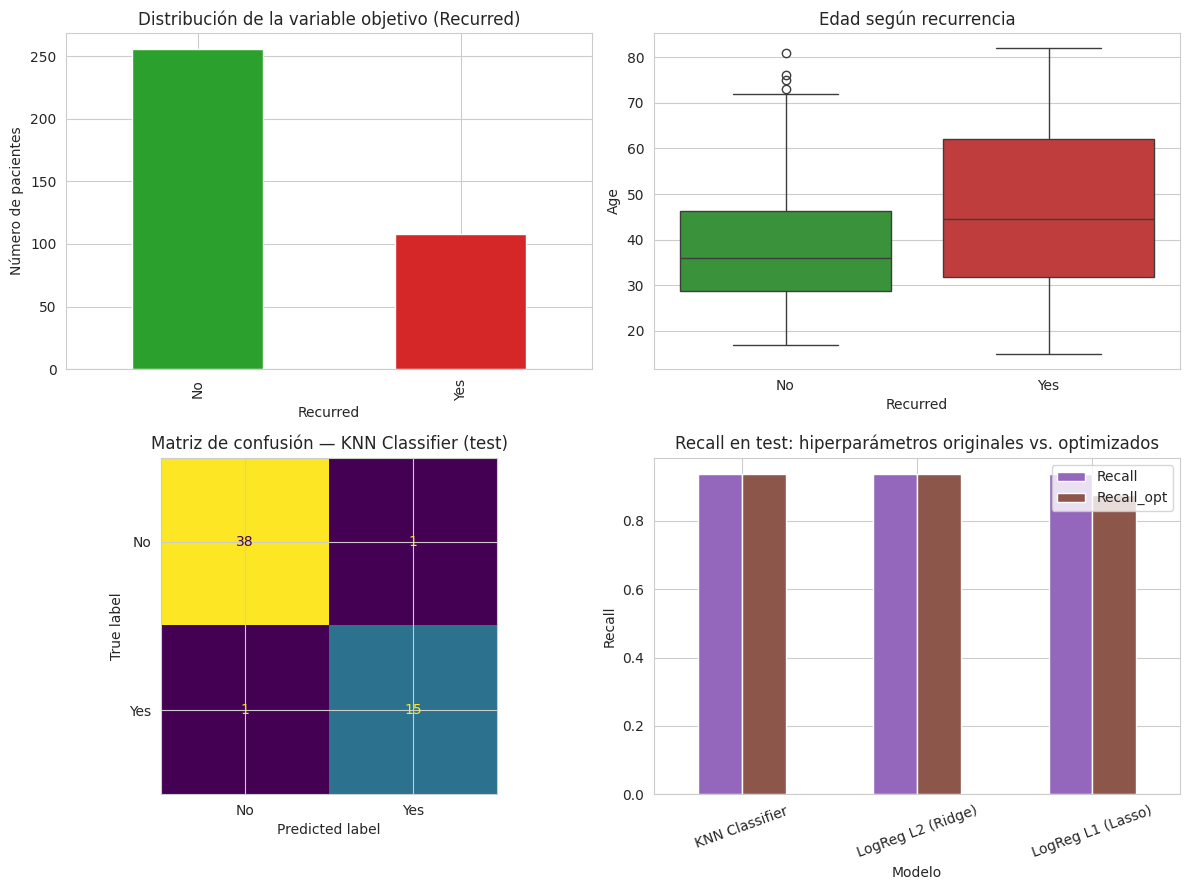

In [33]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# (1) Barras: distribución de la variable objetivo
df['Recurred'].value_counts().plot.bar(ax=axes[0, 0], color=['#2ca02c', '#d62728'])
axes[0, 0].set_title('Distribución de la variable objetivo (Recurred)')
axes[0, 0].set_ylabel('Número de pacientes')

# (2) Boxplot Age vs Recurred
sns.boxplot(data=df, x='Recurred', y='Age', hue='Recurred', ax=axes[0, 1], palette=['#2ca02c', '#d62728'], legend=False)
axes[0, 1].set_title('Edad según recurrencia')

# (3) Matriz de confusion del modelo final en test
cm = confusion_matrix(y_test, modelo_final.predict(X_test))
ConfusionMatrixDisplay(cm, display_labels=le_target.classes_).plot(ax=axes[1, 0], colorbar=False)
axes[1, 0].set_title(f'Matriz de confusión — {modelo_final_nombre} (test)')

# (4) Recall en test: original vs optimizado, por modelo
comparacion_original_vs_opt[['Recall', 'Recall_opt']].plot.bar(ax=axes[1, 1], color=['#9467bd', '#8c564b'])
axes[1, 1].set_title('Recall en test: hiperparámetros originales vs. optimizados')
axes[1, 1].set_ylabel('Recall')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

**Lectura del subplot 2×2:** el panel superior izquierdo recuerda el desbalance de clases que motivó priorizar recall sobre accuracy en todo el análisis. El panel superior derecho resume la relación (moderada) entre edad y recurrencia detectada en el EDA. El panel inferior izquierdo es el resultado más importante desde el punto de vista clínico: muestra exactamente cuántos pacientes con recurrencia real el modelo final detectó correctamente (celda inferior derecha de la matriz) frente a cuántos "se le escaparon" como falsos negativos (celda inferior izquierda) — el número que un comité médico evaluaría con más atención antes de aprobar el uso del modelo. El panel inferior derecho cuantifica el valor concreto que aportó la búsqueda de hiperparámetros de la Fase 7 para cada modelo.
